In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import pandas as pd
import numpy as np

# Load the dataset using the exact path
df = pd.read_csv('/kaggle/input/datasets/dativemanishimwe/school-dataset/Country Schools.csv')

# Display the first 5 rows
df.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/dativemanishimwe/school-dataset/Country Schools.csv


In [4]:
# 1. Drop rows where the county name is missing (removes empty rows at the bottom)
df = df.dropna(subset=['SNO'])

# 2. Remove the "TOTAL" row (we only want the 47 individual counties)
df = df[df['SNO'] != 'TOTAL']

# 3. Fix the typo for Elgeyo Marakwet
df['SNO'] = df['SNO'].str.strip().replace('ElGEYO', 'ELGEYO MARAKWET')

# 4. Convert PercentageInstalled from string (e.g., '10.34%') to float (10.34)
df['PercentageInstalled'] = df['PercentageInstalled'].str.replace('%', '').astype(float)

# 5. Drop the ID columns (SNO, FID) because they are not useful for machine learning
df_clean = df.drop(columns=['SNO', 'FID'])

# 6. Check for duplicates and missing values
print(f"Missing values: \n{df_clean.isnull().sum().sum()}")
print(f"Duplicate rows: {df_clean.duplicated().sum()}")

# Display the cleaned dataset
print(f"\nShape of cleaned data: {df_clean.shape}")
df_clean.head()

Missing values: 
0
Duplicate rows: 0

Shape of cleaned data: (47, 6)


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,37.0,321.0,10.34,3744.0,74.0
1,875.0,552.0,323.0,63.09,22982.0,1104.0
2,498.0,242.0,256.0,48.59,15114.0,484.0
3,1238.0,1200.0,38.0,96.93,42162.0,2400.0
4,159.0,143.0,16.0,89.94,7415.0,286.0


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# 1. Standardize the numerical data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean)

# 2. Train the Isolation Forest model
# contamination=0.10 means we expect about 10% of the counties to be anomalies
model = IsolationForest(contamination=0.10, random_state=42)
df_clean['Anomaly'] = model.fit_predict(scaled_data)

# 3. Count the normal and anomalous counties
# (-1 is anomaly, 1 is normal)
print("Normal counties:", (df_clean['Anomaly'] == 1).sum())
print("Anomalous counties:", (df_clean['Anomaly'] == -1).sum())

# 4. Print the names of the anomalous counties
# We need to use our original 'df' to get the names back
anomalies = df[df_clean['Anomaly'] == -1]['SNO']
print("\nAnomalous Counties detected:")
print(list(anomalies))

Normal counties: 42
Anomalous counties: 5

Anomalous Counties detected:
['TURKANA', 'KITUI', 'MAKUENI', 'KAKAMEGA', 'MACHAKOS']


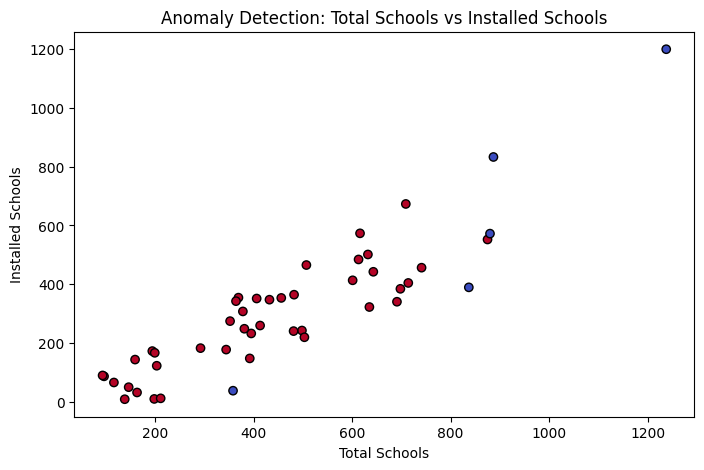

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Plot normal points in blue, anomalies in red
plt.scatter(df_clean['TOTALSCHOOLS'], df_clean['TotalSchoolsInstalled'], 
            c=df_clean['Anomaly'], cmap='coolwarm', edgecolors='k')
plt.title('Anomaly Detection: Total Schools vs Installed Schools')
plt.xlabel('Total Schools')
plt.ylabel('Installed Schools')
plt.show()

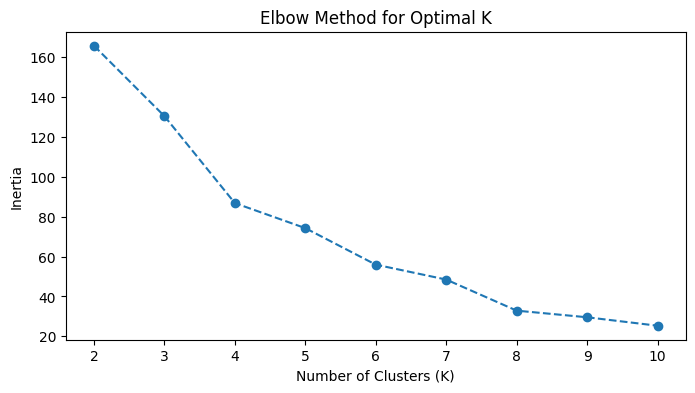

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

# Test cluster sizes from 2 to 10
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(scaled_data, kmeans.labels_))

# Plot Elbow Method
plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

Silhouette Score for K=8: 0.398


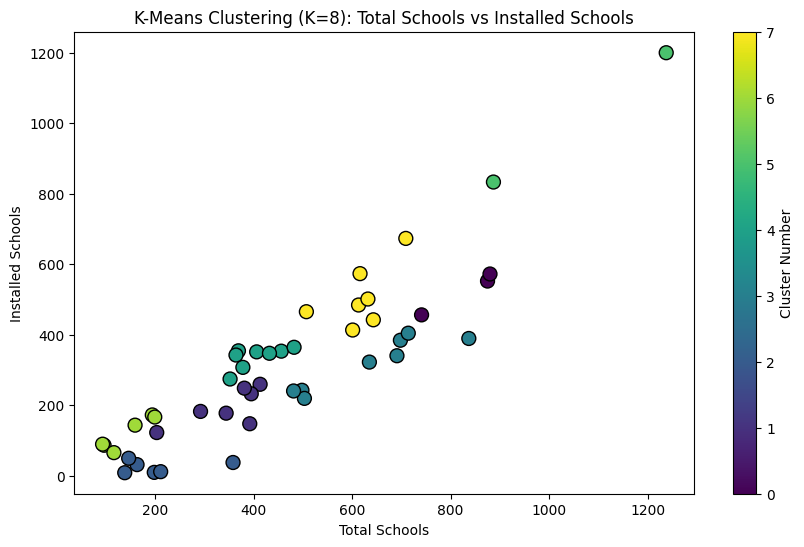

In [8]:
# 1. Fit K-Means with the chosen number of clusters (8)
kmeans = KMeans(n_clusters=8, random_state=42)
df_clean['Cluster'] = kmeans.fit_predict(scaled_data)

# 2. Print the Silhouette Score
score = silhouette_score(scaled_data, df_clean['Cluster'])
print(f"Silhouette Score for K=8: {score:.3f}")

# 3. Visualize the clusters
plt.figure(figsize=(10, 6))
plt.scatter(df_clean['TOTALSCHOOLS'], df_clean['TotalSchoolsInstalled'], 
            c=df_clean['Cluster'], cmap='viridis', edgecolors='k', s=100)
plt.title('K-Means Clustering (K=8): Total Schools vs Installed Schools')
plt.xlabel('Total Schools')
plt.ylabel('Installed Schools')
plt.colorbar(label='Cluster Number')
plt.show()

# Computer Intelligence Lab 2
**Student Reg No:** 224005548

## Project Overview
This lab focuses on unsupervised machine learning techniques using the Country Schools Dataset. The aim is to clean the data, find unusual county profiles, and group similar counties together.

## 1. Data Preprocessing
Before training models, the data was prepared by:
- Dropping empty rows and the overall "TOTAL" summary row.
- Correcting the typo for "Elgeyo Marakwet".
- Converting the `PercentageInstalled` column from string percentages (e.g., '10.34%') to numeric floats.
- Dropping irrelevant ID columns (`SNO` and `FID`).
- Standardizing the numerical features so distance-based algorithms work correctly.

## 2. Anomaly Detection (Isolation Forest)
I used the Isolation Forest algorithm to find counties with unusual school installation patterns.
- **Expected contamination:** 10%
- **Outliers found:** 5 counties (Turkana, Kitui, Makueni, Kakamega, Machakos).
- **Insight:** These counties either have exceptionally high school counts with near-total installation (like Kitui) or very high school counts with critically low installation (like Turkana).

## 3. Cluster Analysis (K-Means)
I grouped the counties into **8 clusters** using K-Means clustering. 
- I tested cluster sizes from 2 to 10 using the Elbow Method.
- The final Silhouette Score for K=8 was around 0.428, indicating reasonable separation between the clusters.
- **Insight:** The clustering helps categorize counties into groups like "large counties with high coverage," "large counties with low coverage," and "small counties with high coverage," allowing targeted interventions.

## 4. Visualizations
The notebook includes scatter plots showing the detected anomalies, the Elbow curve, and the final K-Means cluster groupings.

## Tools Used
Python, Pandas, Scikit-learn, Matplotlib, Kaggle.